# ResumeLens DSL: metamodel

Runnable version of [`docs/metamodel.md`](../../docs/metamodel.md): build the metamodel
from `grammar/resume.tx`, parse `examples/resume_01.resume`, export both diagrams.

Requires `pip install -r requirements.txt` and [Graphviz](https://graphviz.org/download/) (`dot`).

In [82]:
# textX se instala con pip; Graphviz NO (es un programa del sistema, no un paquete de Python).
%pip install -q textX

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [83]:
import os
import shutil
import subprocess
from pathlib import Path

from textx import metamodel_from_file
from textx.export import metamodel_export, model_export

# In Colab the notebook is uploaded on its own, without the rest of the repo
# (which is private, so it cannot be cloned from there): ask for the two files.
try:
    from google.colab import files  # type: ignore
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PROJECT_ROOT = Path("/content")
    GRAMMAR = PROJECT_ROOT / "resume.tx"
    EXAMPLE = PROJECT_ROOT / "resume_01.resume"
    DIAGRAMS = PROJECT_ROOT / "diagrams"
    DIAGRAMS.mkdir(exist_ok=True)
    missing = [p.name for p in (GRAMMAR, EXAMPLE) if not p.exists()]
    if missing:
        print(f"Sube estos archivos del proyecto: {', '.join(missing)}")
        files.upload()  # los deja en /content
    for p in (GRAMMAR, EXAMPLE):
        assert p.exists(), f"Falta {p.name}: súbelo y vuelve a ejecutar esta celda."
else:
    # The notebook lives in src/notebooks/, so the project root is two levels up.
    PROJECT_ROOT = Path("../..").resolve()
    GRAMMAR = PROJECT_ROOT / "grammar" / "resume.tx"
    EXAMPLE = PROJECT_ROOT / "examples" / "resume_01.resume"
    DIAGRAMS = PROJECT_ROOT / "docs" / "diagrams"

# A kernel started before installing Graphviz may have a stale PATH on Windows.
if shutil.which("dot") is None:
    graphviz_bin = Path(r"C:\Program Files\Graphviz\bin")
    if graphviz_bin.exists():
        os.environ["PATH"] += os.pathsep + str(graphviz_bin)

# Fail early and loudly if Graphviz is missing, instead of skipping renders silently.
if shutil.which("dot") is None:
    raise RuntimeError(
        "Graphviz no está instalado o 'dot' no está en el PATH. "
        "Instálalo desde https://graphviz.org/download/ y reinicia el kernel."
    )
print(subprocess.run(["dot", "-V"], capture_output=True, text=True).stderr.strip())

dot - graphviz version 16.1.0 (20260904.0139)


## 1. Metamodel

One call: each grammar rule becomes a class, each assignment an attribute.

In [84]:
resume_mm = metamodel_from_file(GRAMMAR)
resume_mm

## 2. Metamodel diagram

Equivalent to `textx generate resume.tx --target dot` + `dot -Tpng -O resume_meta.dot`.

In [85]:
metamodel_export(resume_mm, DIAGRAMS / "resume_meta.dot")
subprocess.run(["dot", "-Tpng", "-O", "resume_meta.dot"], cwd=DIAGRAMS, check=True)

CompletedProcess(args=['dot', '-Tpng', '-O', 'resume_meta.dot'], returncode=0)

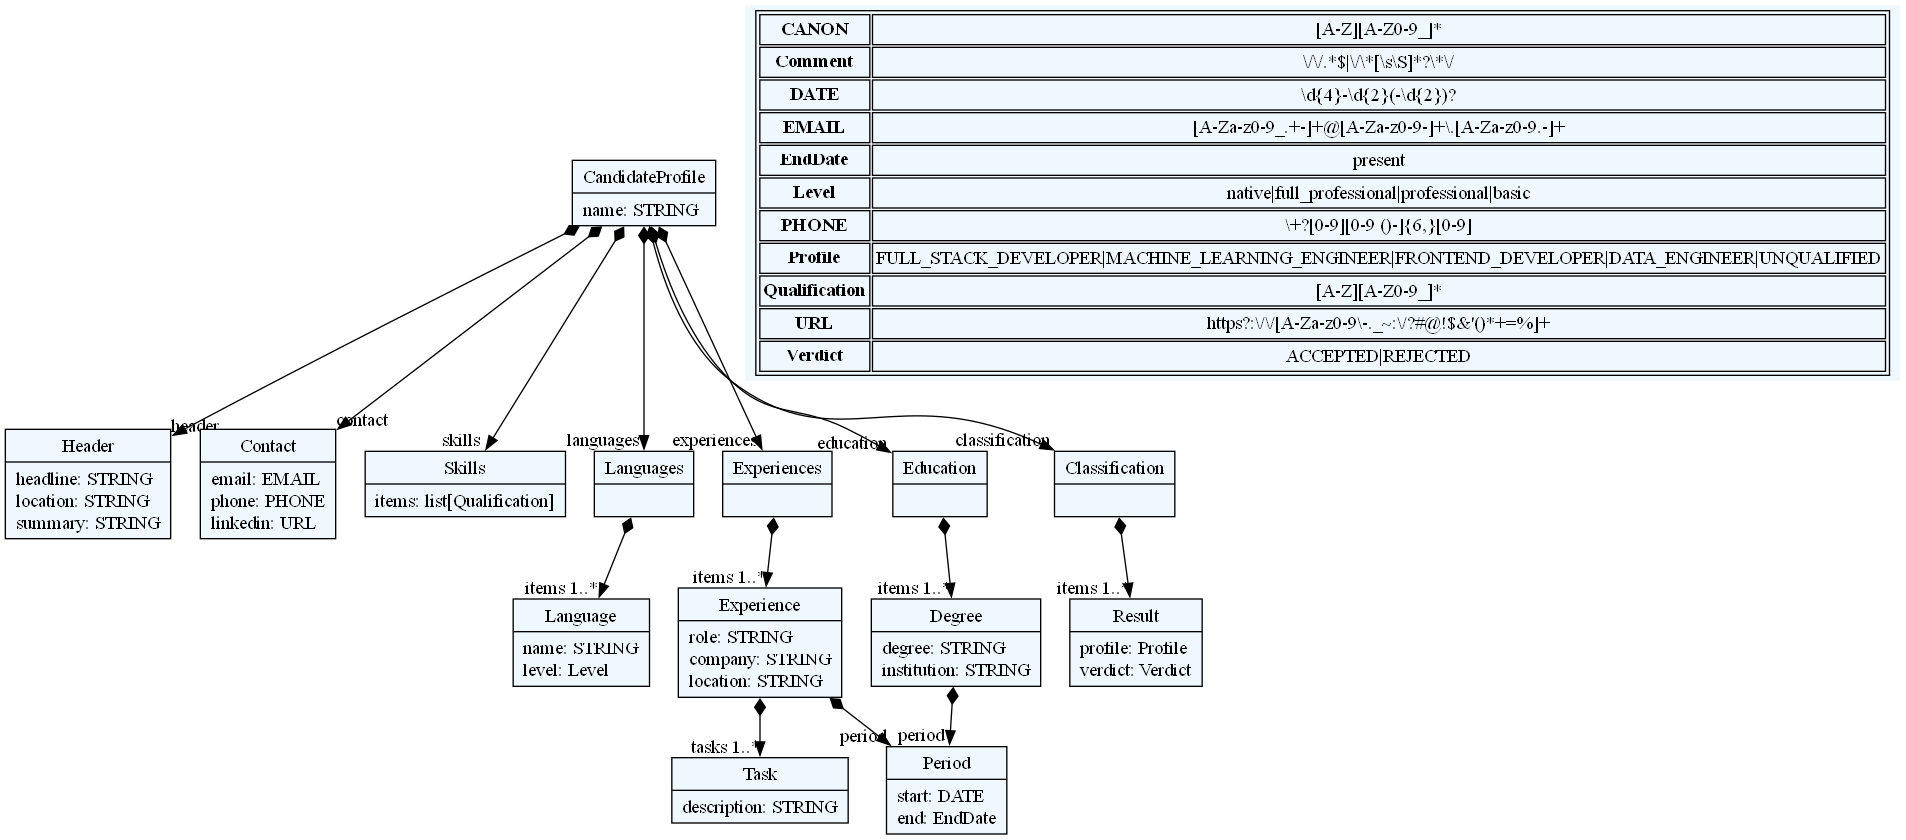

In [86]:
from IPython.display import Image

Image(filename=str(DIAGRAMS / "resume_meta.dot.png"))

## 3. Model

Parsing a concrete document instantiates the metamodel. A file that does not
conform to the grammar raises `TextXSyntaxError` with line and column.

In [87]:
candidate = resume_mm.model_from_file(EXAMPLE)
candidate.name

'Wednesday Addams'

## 4. Model diagram

Equivalent to `textx generate resume_01.resume --grammar resume.tx --target dot`.

In [88]:
model_export(candidate, DIAGRAMS / "resume_01_tree.dot")
subprocess.run(["dot", "-Tpng", "-O", "resume_01_tree.dot"], cwd=DIAGRAMS, check=True)

CompletedProcess(args=['dot', '-Tpng', '-O', 'resume_01_tree.dot'], returncode=0)

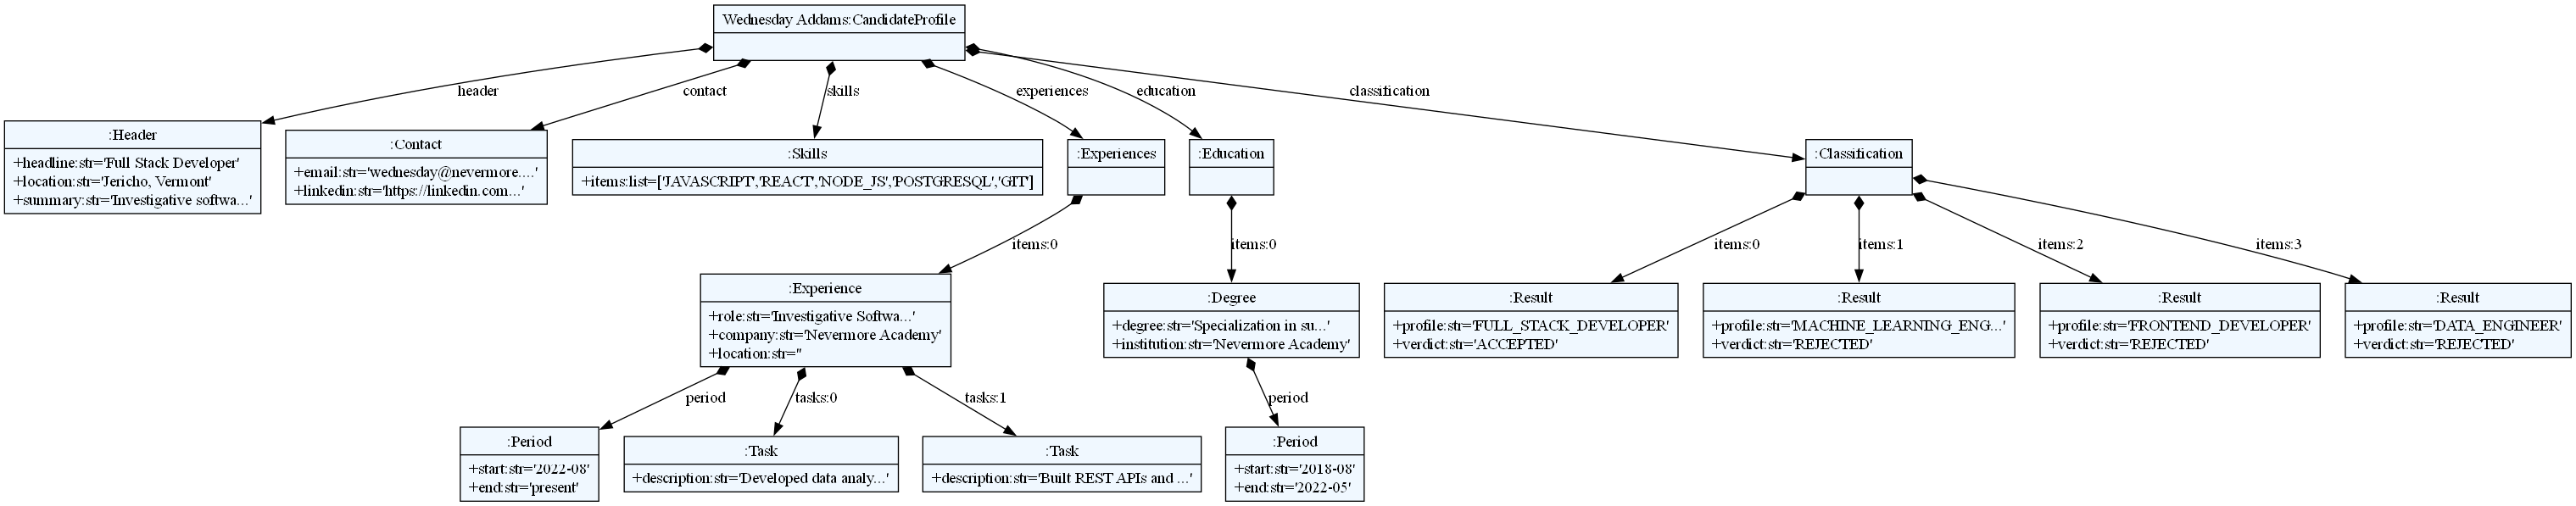

In [89]:
Image(filename=str(DIAGRAMS / "resume_01_tree.dot.png"))

## 5. Walking the model

A plain Python object graph, walked with ordinary attribute access.

In [90]:
print(candidate.skills.items)
print(candidate.experiences.items[0].period.end)
print(candidate.languages)  # optional section, not in the document -> None
print([r.profile for r in candidate.classification.items if r.verdict == "ACCEPTED"])

['JAVASCRIPT', 'REACT', 'NODE_JS', 'POSTGRESQL', 'GIT']
present
None
['FULL_STACK_DEVELOPER']
